# Fase 3 — Torneo de modelos predictivos, calibración e importancia de variables
**Responsable:** Julián Agustín Lozano (Backend & ML) · **Borrador para integrar al notebook maestro (sección 3).**

**Pregunta predictiva:** dado lo que observamos de un cliente, ¿cuál es $P(\text{Churn}=1 \mid X)$? Esta fase *no* responde qué pasa si intervenimos (eso es la Fase 4).

**Protocolo (inmutable):**
1. Partición estratificada **80/20** ya fijada en `artifacts/split_idx.json` (Train 2.385 / Test 597, prevalencia de churn ≈ 17,3% en ambos).
2. Toda búsqueda de hiperparámetros usa `StratifiedKFold(5, shuffle=True, random_state=42)` **solo en Train**, con `Pipeline(preprocesador, modelo)`: la imputación (mediana + indicador de NA), el escalado y el One-Hot se re-ajustan en cada fold.
3. El modelo final se elige por **ROC-AUC media de CV**. Test se usa **una sola vez**, al final.
4. Features: las 18 variables del dataset salvo `CustomerID`, `Churn` y `coupon_any` (redundante con `CouponUsed`). `DaySinceLastOrder` entra en el torneo predictivo aunque sea descendiente de $Y$ en el DAG: sirve para predecir, pero **nunca** entra al ajuste causal.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "borradores" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.tree import plot_tree

from src import RANDOM_STATE
from src import models as mdl
from src import preprocessing as prep

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

df = prep.make_clean_dataset()
X_train, X_test, y_train, y_test = prep.load_split(df)
print(f"Train: {len(X_train)} (churn {y_train.mean():.2%}) | Test: {len(X_test)} (churn {y_test.mean():.2%})")
print(f"Features: {len(mdl.FEATURES)} ({len(mdl.FEATURE_NUMERIC)} numéricas, {len(mdl.FEATURE_CATEGORICAL)} categóricas)")

Train: 2385 (churn 17.32%) | Test: 597 (churn 17.25%)
Features: 18 (12 numéricas, 6 categóricas)


## 3.1 Ejecución del torneo
`run_tournament()` ajusta las cuatro familias con CV en Train, elige la mejor por ROC-AUC de CV, la recalibra (isotónica, CV interna en Train) y evalúa todo en Test una única vez. Tarda alrededor de un minuto.

In [2]:
res = mdl.run_tournament(df)
cv_table = (
    pd.DataFrame(res["cv"]).T.drop(columns="best_params")
    .rename(columns={"cv_roc_auc_mean": "ROC-AUC CV", "cv_roc_auc_std": "± sd", "cv_pr_auc_mean": "PR-AUC CV",
                     "cv_neg_brier_mean": "−Brier CV", "train_roc_auc_mean": "ROC-AUC Train"})
    [["ROC-AUC CV", "± sd", "PR-AUC CV", "−Brier CV", "ROC-AUC Train"]]
)
print("Tabla 3.1 — Desempeño en validación cruzada (StratifiedKFold 5, solo Train)")
cv_table

Tabla 3.1 — Desempeño en validación cruzada (StratifiedKFold 5, solo Train)


,ROC-AUC CV,± sd,PR-AUC CV,−Brier CV,ROC-AUC Train
Logística ElasticNet,0.8935,0.0061,0.7273,-0.0834,0.9051
Naive Bayes,0.7857,0.0194,0.4425,-0.3104,0.7971
CART podado,0.8477,0.0222,0.6075,-0.0947,0.8825
Random Forest,0.932,0.0147,0.8084,-0.0743,1.0


In [3]:
print("Hiperparámetros elegidos por CV:")
for name, s in res["cv"].items():
    print(f"  {name:<22} {s['best_params']}")
print(f"\nMejor modelo por CV: {res['best_name']}")

Hiperparámetros elegidos por CV:
  Logística ElasticNet   {'C': np.float64(100.0), 'l1_ratio': 0.0}
  Naive Bayes            {'var_smoothing': np.float64(0.001)}
  CART podado            {'ccp_alpha': np.float64(0.0019026779902938408)}
  Random Forest          {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15}

Mejor modelo por CV: Random Forest


## 3.2 Familia 1 — Regresión logística regularizada
$$\log\frac{\pi_i}{1-\pi_i} = \beta_0 + x_i^\top\beta, \qquad \pi_i = P(\text{Churn}_i = 1 \mid x_i)$$
Con penalización **ElasticNet** se minimiza $-\ell(\beta) + \frac{1}{C}\left[\rho\,\lVert\beta\rVert_1 + \tfrac{1-\rho}{2}\lVert\beta\rVert_2^2\right]$: $\rho=0$ es Ridge (encoge), $\rho=1$ es Lasso (además anula coeficientes). La grilla cruza $C \in [10^{-3}, 10^{2}]$ con $\rho \in \{0;\,0{,}5;\,1\}$.

La **senda de coeficientes** muestra cómo, al relajar la penalización (C crece), las variables "entran" al modelo: las primeras en entrar son las de mayor señal.

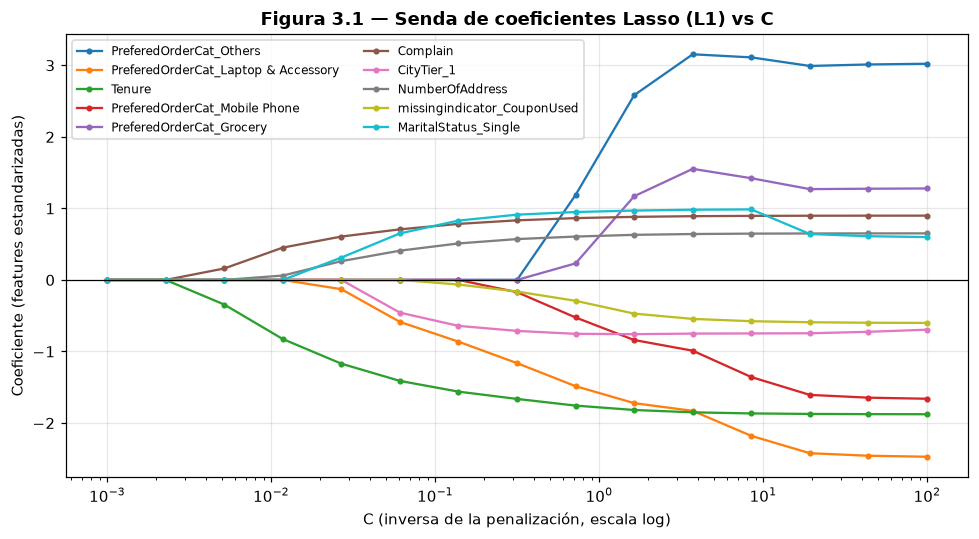

In [4]:
path = mdl.logistic_coef_path(X_train, y_train, l1_ratio=1.0)
top = path.iloc[-1].abs().sort_values(ascending=False).head(10).index
fig, ax = plt.subplots(figsize=(9, 5))
for col in top:
    ax.plot(path.index, path[col], marker=".", label=col)
ax.set_xscale("log")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Figura 3.1 — Senda de coeficientes Lasso (L1) vs C", xlabel="C (inversa de la penalización, escala log)",
       ylabel="Coeficiente (features estandarizadas)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

**Odds ratios con IC 95%** (Logit de `statsmodels` sin penalizar, en Train). La especificación con *todas* las features no converge (cuasi-separación por categorías raras y colinealidad `CouponUsed`–`OrderCount`–`CashbackAmount`), así que se reporta una especificación parsimoniosa con las variables de mayor señal. Interpretación: $OR_j = e^{\beta_j}$ es el factor por el que se multiplican las *odds* de churn ante un aumento de una unidad en $x_j$, manteniendo el resto constante. Esto es **asociación condicional**, no efecto causal.

In [5]:
formula = ("Churn ~ Tenure + Complain + SatisfactionScore + NumberOfAddress + DaySinceLastOrder + CashbackAmount"
           " + C(CityTier) + C(MaritalStatus) + C(PreferedOrderCat)")
or_table = mdl.logit_odds_ratios(pd.concat([X_train, y_train], axis=1), formula).drop(index="Intercept")
print(f"Tabla 3.2 — Odds ratios (Logit, Train, casos completos n = {or_table.attrs['n_obs']}, "
      f"pseudo-R² = {or_table.attrs['pseudo_r2']:.3f})")
or_table.sort_values("OR", ascending=False).round(3)

Tabla 3.2 — Odds ratios (Logit, Train, casos completos n = 2136, pseudo-R² = 0.384)


,beta,OR,IC95_inf,IC95_sup,p_valor
Complain,1.948,7.012,5.141,9.564,0.000
C(PreferedOrderCat)[T.Others],1.877,6.532,1.761,24.236,0.005
C(CityTier)[T.3],1.027,2.792,1.964,3.969,0.000
C(CityTier)[T.2],0.876,2.401,1.135,5.079,0.022
C(MaritalStatus)[T.Single],0.844,2.326,1.618,3.343,0.000
C(PreferedOrderCat)[T.Grocery],0.392,1.480,0.468,4.676,0.504
SatisfactionScore,0.274,1.315,1.166,1.482,0.000
NumberOfAddress,0.242,1.273,1.202,1.348,0.000
CashbackAmount,-0.007,0.993,0.984,1.001,0.073
DaySinceLastOrder,-0.053,0.948,0.901,0.998,0.040


**Lectura:** un reclamo en el último mes multiplica las odds de churn por ≈ 7 (IC 95% ≈ [5,1; 9,6]); cada mes adicional de antigüedad (`Tenure`) las multiplica por ≈ 0,79, es decir, las reduce ≈ 21% por mes.

## 3.3 Familia 2 — Naive Bayes Gaussiano
Supone **independencia condicional** de las features dada la clase:
$$P(X_1,\dots,X_p \mid Y) = \prod_{j=1}^{p} P(X_j \mid Y), \qquad X_j \mid Y=k \sim \mathcal{N}(\mu_{jk}, \sigma^2_{jk})$$
Si dos features están correlacionadas *dentro* de cada clase, el producto cuenta dos veces la misma evidencia y empuja la probabilidad posterior hacia 0 o 1: el **orden** (AUC) puede ser aceptable pero las **probabilidades** quedan descalibradas.

In [6]:
deps = mdl.top_conditional_dependencies(pd.concat([X_train, y_train], axis=1), k=8)
print("Tabla 3.3 — Mayores correlaciones de Spearman DENTRO de cada clase (NB supone que son 0)")
deps.round(3)

Tabla 3.3 — Mayores correlaciones de Spearman DENTRO de cada clase (NB supone que son 0)


,clase,var_1,var_2,spearman
0,0,CouponUsed,OrderCount,0.739
1,1,CouponUsed,OrderCount,0.692
2,1,OrderCount,DaySinceLastOrder,0.580
3,1,OrderCount,CashbackAmount,0.526
4,1,Tenure,CashbackAmount,0.466
5,1,DaySinceLastOrder,CashbackAmount,0.462
6,0,OrderCount,DaySinceLastOrder,0.443
7,0,Tenure,CashbackAmount,0.427


## 3.4 Familia 3 — Árbol CART: sobreajuste y poda por complejidad de costo
Un árbol sin restricciones crece hasta hojas puras: memoriza Train. La poda minimiza
$$R_\alpha(T) = R(T) + \alpha\,|\tilde T|$$
donde $R(T)$ es el error (impureza) del árbol y $|\tilde T|$ su número de hojas. `cost_complexity_pruning_path` devuelve los valores de $\alpha$ en los que el árbol óptimo cambia; se elige $\alpha$ por CV (y se informa también la **regla 1-SE**: el $\alpha$ más grande, es decir el árbol más simple, cuyo AUC está a menos de un error estándar del mejor).

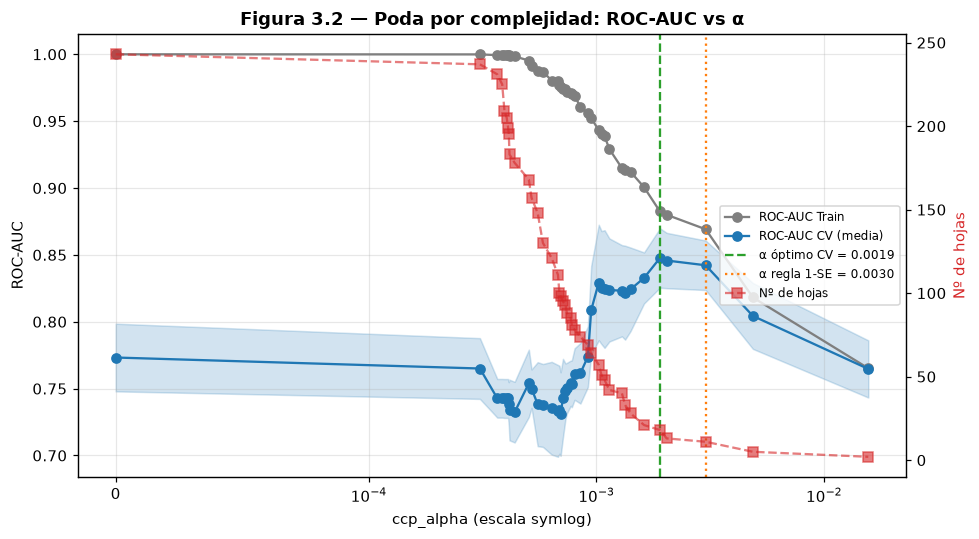

Árbol sin podar: ROC-AUC Train = 1.000 | Test = 0.807
Árbol podado:    ROC-AUC Test = 0.836 (18 hojas)


In [7]:
t = res["ccp_table"]
best_alpha = res["cv"]["CART podado"]["best_params"]["ccp_alpha"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(t.ccp_alpha, t.train_roc_auc, "o-", color="tab:gray", label="ROC-AUC Train")
ax.plot(t.ccp_alpha, t.cv_roc_auc, "o-", color="tab:blue", label="ROC-AUC CV (media)")
ax.fill_between(t.ccp_alpha, t.cv_roc_auc - t.cv_roc_auc_std, t.cv_roc_auc + t.cv_roc_auc_std, alpha=0.2, color="tab:blue")
ax.axvline(best_alpha, color="tab:green", ls="--", label=f"α óptimo CV = {best_alpha:.4f}")
ax.axvline(res["ccp_alpha_1se"], color="tab:orange", ls=":", label=f"α regla 1-SE = {res['ccp_alpha_1se']:.4f}")
ax.set_xscale("symlog", linthresh=1e-4)
ax.set(title="Figura 3.2 — Poda por complejidad: ROC-AUC vs α", xlabel="ccp_alpha (escala symlog)", ylabel="ROC-AUC")
ax2 = ax.twinx()
ax2.plot(t.ccp_alpha, t.n_hojas, "s--", color="tab:red", alpha=0.6, label="Nº de hojas")
ax2.set_ylabel("Nº de hojas", color="tab:red")
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="center right")
plt.tight_layout()
plt.show()
print(f"Árbol sin podar: ROC-AUC Train = {res['unpruned_train_auc']:.3f} | Test = {res['test'].loc['CART sin podar', 'roc_auc']:.3f}")
print(f"Árbol podado:    ROC-AUC Test = {res['test'].loc['CART podado', 'roc_auc']:.3f} "
      f"({res['models']['CART podado'].named_steps['model'].get_n_leaves()} hojas)")

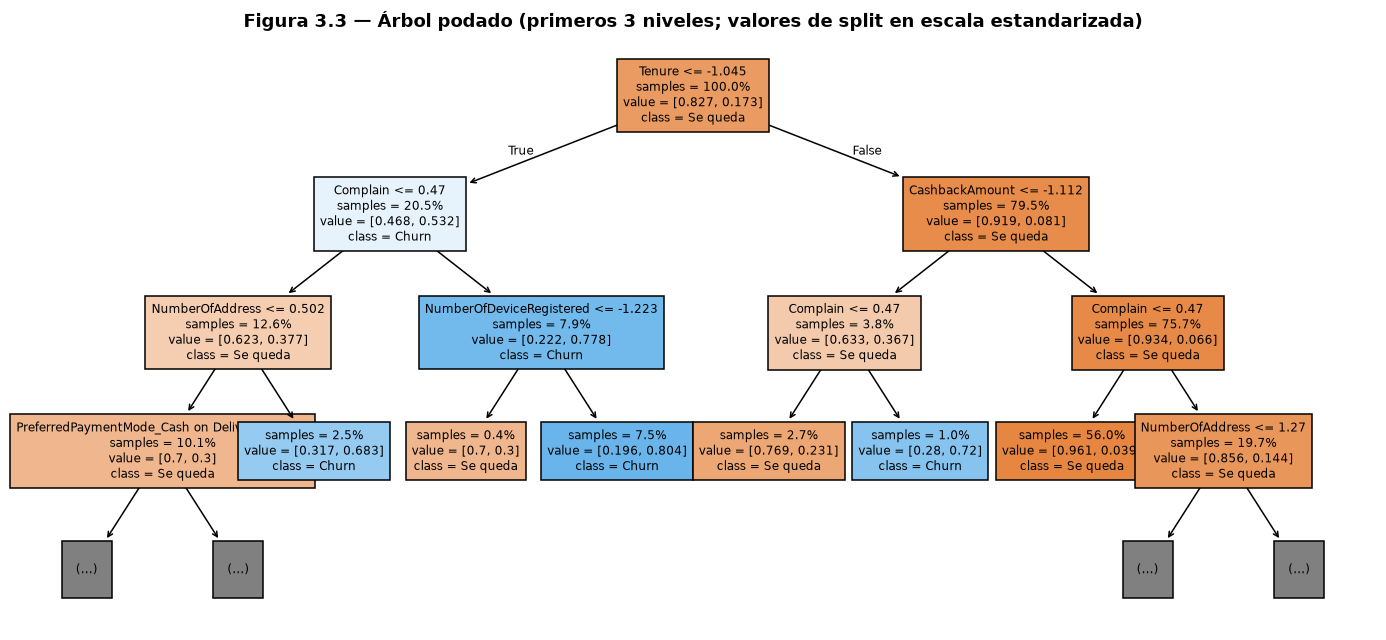

Nodo raíz: Tenure <= 1.50


In [8]:
pruned = res["models"]["CART podado"]
pre, tree = pruned.named_steps["pre"], pruned.named_steps["model"]
names = pre.get_feature_names_out()
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree, max_depth=3, feature_names=names, class_names=["Se queda", "Churn"], filled=True,
          proportion=True, impurity=False, fontsize=8, ax=ax)
ax.set_title("Figura 3.3 — Árbol podado (primeros 3 niveles; valores de split en escala estandarizada)")
plt.show()

# Regla del nodo raíz en unidades originales
num_pipe = pre.named_transformers_["num"]
num_names = list(num_pipe.get_feature_names_out())
root_name, root_thr = names[tree.tree_.feature[0]], tree.tree_.threshold[0]
if root_name in num_names:
    i = num_names.index(root_name)
    scaler = num_pipe.named_steps["scaler"]
    root_thr = scaler.mean_[i] + root_thr * scaler.scale_[i]
print(f"Nodo raíz: {root_name} <= {root_thr:.2f}")

**Interpretación del nodo raíz:** el primer corte separa a los clientes nuevos (antigüedad baja) del resto: es la partición que más reduce la impureza de Gini, en línea con el OR de `Tenure` y con su importancia por permutación (sección 3.7).

## 3.5 Familia 4 — Random Forest, búsqueda de hiperparámetros y error OOB
`RandomizedSearchCV` (25 combinaciones × 5 folds) sobre `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf` y `max_features` ∈ {sqrt, log2, 0,3, 0,5}.

Cada árbol se entrena con una muestra *bootstrap*: ≈ 36,8% ($\approx e^{-1}$) de los clientes queda **fuera de bolsa** (OOB) y sirve como validación "gratis". Si el bosque no sobreajusta la selección, el desempeño OOB debería converger al de la CV.

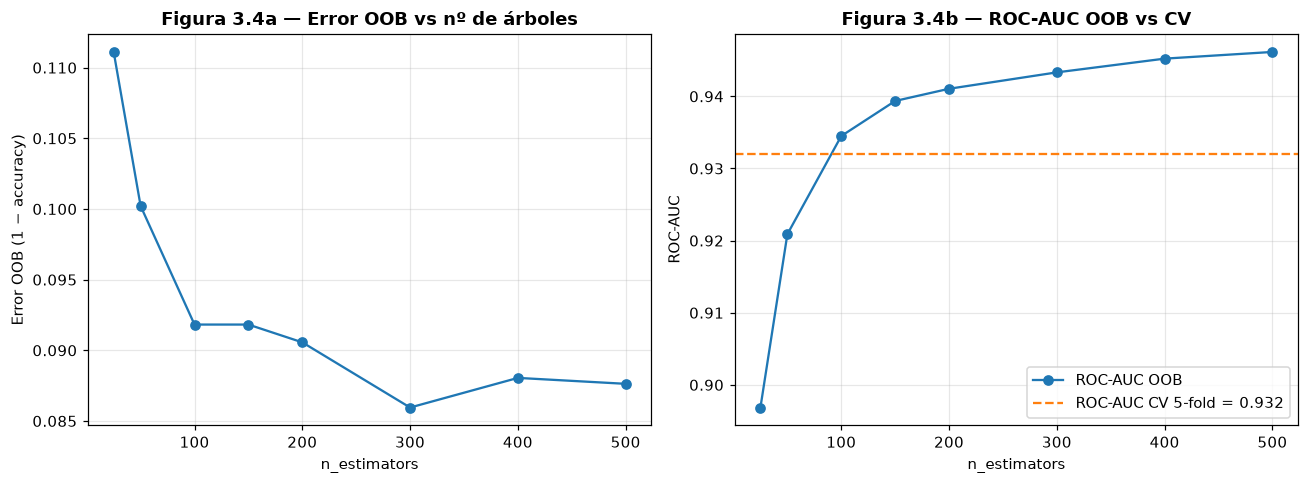

OOB del RF elegido: {'oob_accuracy': 0.909433962264151, 'oob_roc_auc': 0.9410524583883817}


In [9]:
curve = mdl.oob_convergence(res["models"]["Random Forest"], X_train, y_train)
cv_auc = res["cv"]["Random Forest"]["cv_roc_auc_mean"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(curve.n_estimators, curve.oob_error, "o-")
axes[0].set(title="Figura 3.4a — Error OOB vs nº de árboles", xlabel="n_estimators", ylabel="Error OOB (1 − accuracy)")
axes[1].plot(curve.n_estimators, curve.oob_roc_auc, "o-", label="ROC-AUC OOB")
axes[1].axhline(cv_auc, color="tab:orange", ls="--", label=f"ROC-AUC CV 5-fold = {cv_auc:.3f}")
axes[1].set(title="Figura 3.4b — ROC-AUC OOB vs CV", xlabel="n_estimators", ylabel="ROC-AUC")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"OOB del RF elegido: {res['rf_oob']}")

## 3.6 Evaluación en Test (una única vez) y calibración
Métricas de umbral (con corte 0,5): precision, recall, F1 de la clase churn, F1 macro y ponderado. Métricas de ranking: ROC-AUC (con IC 95% por bootstrap, 1.000 réplicas) y PR-AUC, más informativa con clases desbalanceadas. Métricas de calibración: **Brier** $= \frac1n\sum_i(\hat p_i - y_i)^2$ y **ECE** (error esperado de calibración, 10 bins por cuantiles).

El modelo ganador por CV (RF) se recalibra con regresión **isotónica** (`CalibratedClassifierCV`, 5 folds en Train): es el *modelo de resguardo* para que las probabilidades sean utilizables en decisiones.

In [10]:
test = res["test"]
print("Tabla 3.4 — Matriz comparativa en Test (n = 597)")
test[["precision", "recall", "f1", "f1_macro", "f1_ponderado", "roc_auc", "roc_auc_ic95_inf", "roc_auc_ic95_sup",
      "pr_auc", "brier", "ece"]].round(3)

Tabla 3.4 — Matriz comparativa en Test (n = 597)


,precision,recall,f1,f1_macro,f1_ponderado,roc_auc,roc_auc_ic95_inf,roc_auc_ic95_sup,pr_auc,brier,ece
modelo,,,,,,,,,,,
CART sin podar,0.587,0.718,0.646,0.781,0.870,0.807,0.760,0.849,0.471,0.136,0.039
Logística ElasticNet,0.684,0.505,0.581,0.754,0.867,0.887,0.852,0.921,0.682,0.090,0.022
Naive Bayes,0.269,0.796,0.402,0.546,0.640,0.754,0.698,0.805,0.443,0.322,0.365
CART podado,0.612,0.505,0.553,0.735,0.854,0.836,0.793,0.879,0.508,0.107,0.049
Random Forest,0.855,0.573,0.686,0.817,0.902,0.943,0.916,0.968,0.819,0.072,0.079
Random Forest + isotónica,0.783,0.631,0.699,0.822,0.902,0.946,0.922,0.968,0.806,0.064,0.018


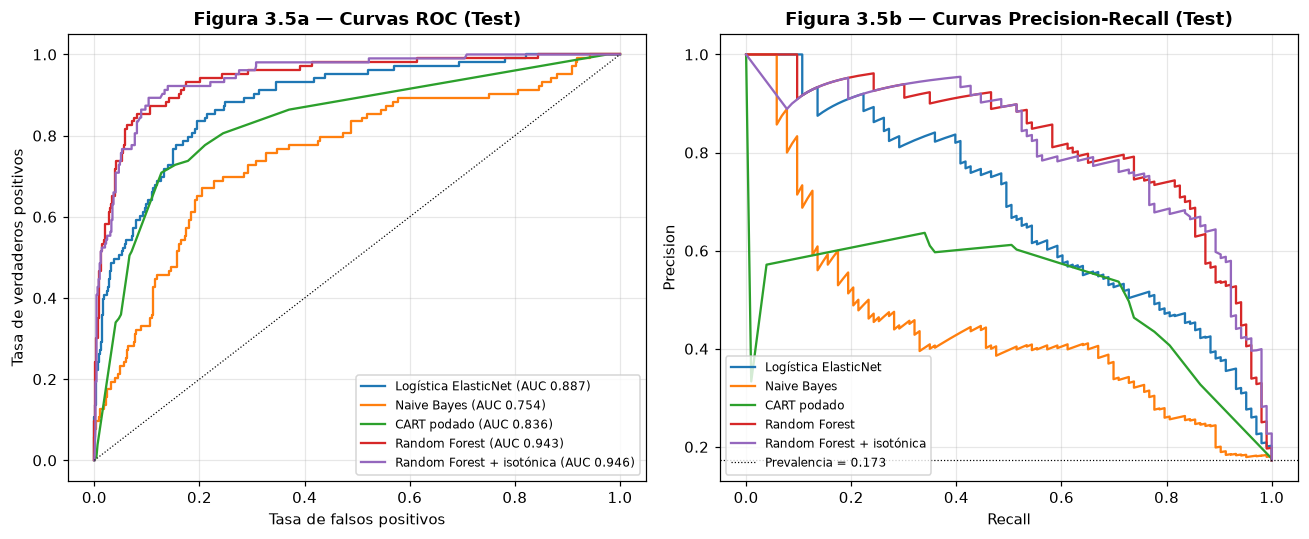

In [11]:
models = {**res["models"], f"{res['best_name']} + isotónica": res["best_calibrated"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, m in models.items():
    p = m.predict_proba(X_test[mdl.FEATURES])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {test.loc[name, 'roc_auc']:.3f})")
    axes[1].plot(rec, prec, label=name)
axes[0].plot([0, 1], [0, 1], "k:", lw=0.8)
axes[0].set(title="Figura 3.5a — Curvas ROC (Test)", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
axes[1].axhline(y_test.mean(), color="k", ls=":", lw=0.8, label=f"Prevalencia = {y_test.mean():.3f}")
axes[1].set(title="Figura 3.5b — Curvas Precision-Recall (Test)", xlabel="Recall", ylabel="Precision")
for a in axes:
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

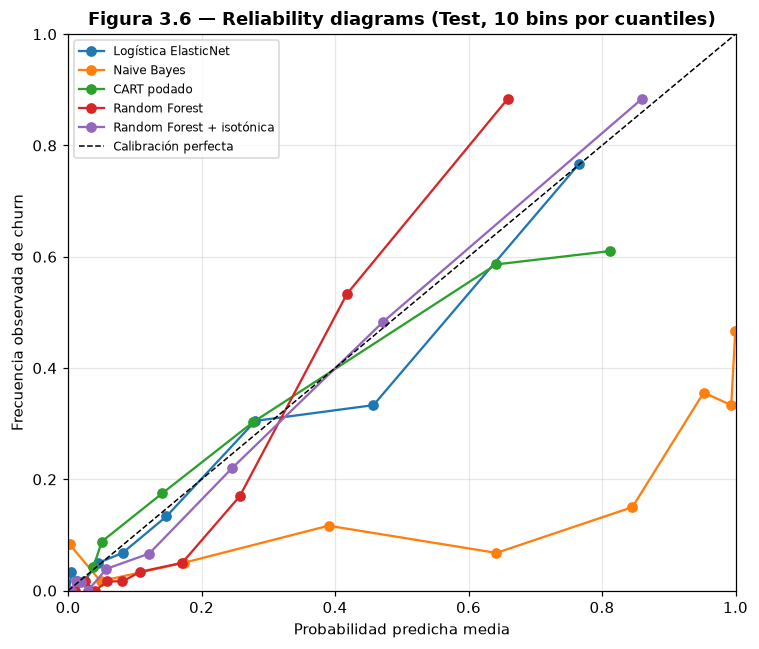

In [12]:
rel = mdl.reliability_curves(models, X_test, y_test)
fig, ax = plt.subplots(figsize=(7, 6))
for name, g in rel.groupby("modelo", sort=False):
    ax.plot(g.prob_media, g.frecuencia_observada, "o-", label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Calibración perfecta")
ax.set(title="Figura 3.6 — Reliability diagrams (Test, 10 bins por cuantiles)", xlabel="Probabilidad predicha media",
       ylabel="Frecuencia observada de churn", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura:** Naive Bayes está muy por debajo de la diagonal (sobre-predice churn: Brier 0,32, ECE 0,37), consecuencia directa de la dependencia `CouponUsed`–`OrderCount` de la Tabla 3.3. El RF sin calibrar ordena muy bien pero comprime las probabilidades; la calibración isotónica lo acerca a la diagonal (ECE 0,079 → 0,018) sin perder AUC. El árbol sin podar: AUC 1,000 en Train vs 0,807 en Test, el sobreajuste esperado.

## 3.7 Explicabilidad: MDI vs Permutation Importance
**MDI (Gini)** suma, sobre todos los nodos que dividen por $X_j$, la reducción de impureza ponderada por la fracción de muestras que llegan al nodo, y promedia sobre los árboles:
$$\text{MDI}(X_j) = \frac{1}{B}\sum_{b=1}^{B}\ \sum_{t \in b:\ v(t)=j} \frac{n_t}{n}\,\Delta G(t)$$
**Sesgo:** una variable continua con $m$ valores distintos ofrece $m-1$ cortes candidatos; una dummy, uno solo. Al elegir en cada nodo el *mejor* corte entre muchos, las variables de alta cardinalidad obtienen reducciones de impureza grandes **por azar** (un problema de comparaciones múltiples), y además MDI se calcula **en Train**, de modo que también premia el sobreajuste (Strobl et al., 2007).

**Permutation importance en Test:** $\text{PI}(X_j) = \text{AUC}_{\text{Test}} - \mathbb{E}\big[\text{AUC}_{\text{Test}}(X_j \text{ permutada})\big]$. Mide la caída real de desempeño fuera de muestra, así que no depende de cuántos cortes ofrece la variable. Su limitación: con features correlacionadas reparte la importancia entre ellas.

**Experimento de control:** se agregan una columna de ruido continuo y una de ruido binario, ambas sin relación con el churn.

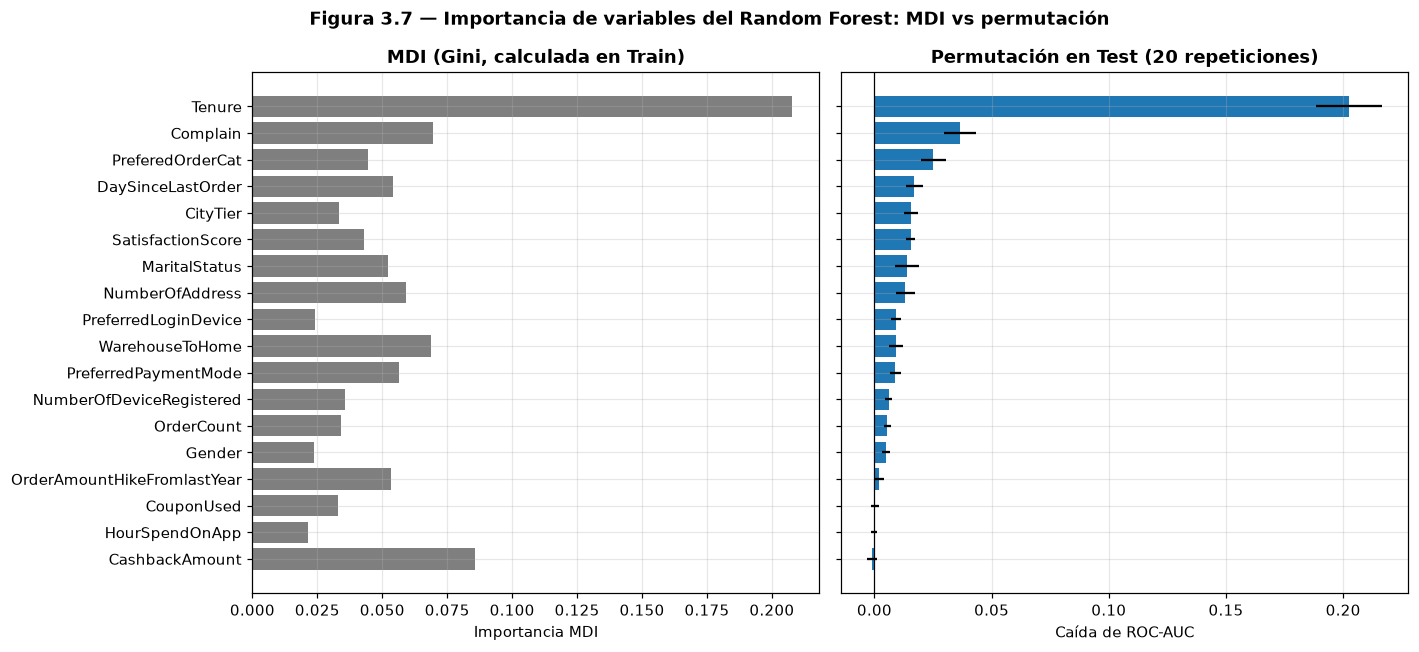

Tabla 3.5 — Rankings MDI vs permutación


,mdi,rank_mdi,perm_mean,perm_std,rank_perm
Tenure,0.2078,1,0.2024,0.0142,1
Complain,0.0697,3,0.0365,0.0068,2
PreferedOrderCat,0.0445,10,0.0251,0.0053,3
DaySinceLastOrder,0.0540,7,0.0170,0.0037,4
CityTier,0.0334,14,0.0156,0.0030,5
SatisfactionScore,0.0430,11,0.0154,0.0018,6
MaritalStatus,0.0523,9,0.0140,0.0050,7
NumberOfAddress,0.0591,5,0.0132,0.0041,8
PreferredLoginDevice,0.0243,16,0.0094,0.0022,9
WarehouseToHome,0.0689,4,0.0092,0.0029,10


In [13]:
imp = mdl.importance_mdi_vs_permutation(res["models"]["Random Forest"], X_test, y_test)
order = imp.sort_values("perm_mean").index
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
axes[0].barh(order, imp.loc[order, "mdi"], color="tab:gray")
axes[0].set(title="MDI (Gini, calculada en Train)", xlabel="Importancia MDI")
axes[1].barh(order, imp.loc[order, "perm_mean"], xerr=imp.loc[order, "perm_std"], color="tab:blue")
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set(title="Permutación en Test (20 repeticiones)", xlabel="Caída de ROC-AUC")
fig.suptitle("Figura 3.7 — Importancia de variables del Random Forest: MDI vs permutación", fontweight="bold")
plt.tight_layout()
plt.show()
print("Tabla 3.5 — Rankings MDI vs permutación")
imp[["mdi", "rank_mdi", "perm_mean", "perm_std", "rank_perm"]].round(4)

In [14]:
noise = mdl.mdi_noise_experiment(res["models"]["Random Forest"], X_train, y_train, X_test, y_test)
print("Tabla 3.6 — Experimento de control con columnas de ruido (20 features)")
noise.loc[["ruido_continuo", "ruido_binario", "Tenure", "Complain", "CashbackAmount"],
          ["mdi", "rank_mdi", "perm_mean", "rank_perm"]].round(4)

Tabla 3.6 — Experimento de control con columnas de ruido (20 features)


,mdi,rank_mdi,perm_mean,rank_perm
ruido_continuo,0.0581,5,0.0001,19
ruido_binario,0.0120,20,0.0019,17
Tenure,0.1927,1,0.2094,1
Complain,0.0711,3,0.0378,2
CashbackAmount,0.0796,2,0.0003,18


**Lectura:** `CashbackAmount` (continua, cientos de valores distintos) es la **#2 por MDI** pero la **#18 por permutación** (≈ 0). El ruido continuo, que por construcción no tiene relación con el churn, recibe una importancia MDI comparable a variables reales, mientras su importancia por permutación es ≈ 0. El ruido binario, en cambio, queda último en ambas. El sesgo de cardinalidad de MDI queda así demostrado empíricamente, y la jerarquía de permutación en Test es la que se usa en la app.

## 3.8 Conclusiones de la Fase 3
- **Modelo de producción:** Random Forest + calibración isotónica. ROC-AUC Test 0,946 (IC 95% por bootstrap en la Tabla 3.4), PR-AUC 0,81, Brier 0,064, ECE 0,018. Se eligió por CV (0,932); el OOB (0,941) confirma la estimación.
- La logística (AUC 0,887) es la mejor alternativa interpretable: un reclamo multiplica las odds de churn por ≈ 7.
- **Predictores principales (permutación):** `Tenure` ≫ `Complain` > `PreferedOrderCat` > `DaySinceLastOrder`. `CouponUsed` aporta ≈ 0 a la predicción.
- **Advertencia:** que una variable prediga bien no implica que intervenirla cambie el churn. Esa pregunta se responde en la Fase 4.